# Báo Cáo Khảo Sát & Trực Quan Hóa Dữ Liệu Chữ Số Viết Tay MNIST
**Môn học:** Phát Triển Hệ Thống Thông Minh (Intelligent System Development)  
**Bài tập 04:** Khám phá & Trực quan hóa dữ liệu thị giác máy tính trước khi huấn luyện mô hình mạng nơ-ron

---

### Mục tiêu khảo sát:
1. **Khảo sát cấu trúc & kiểm toán phân phối lớp:** Đánh giá độ cân bằng giữa 10 lớp chữ số (0 đến 9) trên cả tập huấn luyện (60,000 mẫu) và tập kiểm thử (10,000 mẫu).
2. **Trưng bày thư viện ảnh đa dạng:** Hiển thị lưới mẫu ngẫu nhiên (10 hàng × 10 cột) để quan sát các phong cách viết tay, độ dày nét chữ và độ nghiêng.
3. **Phân tích cường độ điểm ảnh & độ thưa (Sparsity):** Khảo sát phân bố giá trị pixel (0 đến 255), tỉ lệ điểm ảnh nền so với nét mực.
4. **Xây dựng ảnh nguyên mẫu trung bình & bản đồ biến thiên:** Xác định hình thái chuẩn (Mean Image) và các vùng biến thiên nét chữ mạnh nhất (Standard Deviation Heatmap) của từng chữ số.
5. **Giảm chiều dữ liệu & biểu diễn không gian đặc trưng (PCA 2D):** Chiếu không gian 784 chiều về 2 chiều để quan sát mức độ phân tách cụm giữa các chữ số và các vùng nhập nhằng (như 4 - 9, 3 - 5).


In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA

# Cấu hình hạt giống ngẫu nhiên để tái lập kết quả
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Cấu hình giao diện biểu đồ chuyên nghiệp
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

# Thiết lập thư mục lưu trữ biểu đồ báo cáo
FIGURES_DIR = '../reports/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
print(f"Môi trường đồ họa sẵn sàng. Thư mục lưu biểu đồ: {FIGURES_DIR}")


Môi trường đồ họa sẵn sàng. Thư mục lưu biểu đồ: ../reports/figures


### 1. Nạp Dữ Liệu & Kiểm Tra Cấu Trúc
Tập dữ liệu MNIST có thể được nạp từ file nén mảng số `mnist.npz` (tối ưu tốc độ) hoặc đọc từ các file ảnh `.png` thực tế đã lưu trong thư mục `../data/train/` và `../data/test/`.


In [2]:
# Đường dẫn dữ liệu
DATA_NPZ = '../data/mnist.npz'
TRAIN_DIR = '../data/train'
TEST_DIR = '../data/test'

if not os.path.exists(DATA_NPZ):
    DATA_NPZ = 'src/Assigment 04/mnist/data/mnist.npz'
    TRAIN_DIR = 'src/Assigment 04/mnist/data/train'
    TEST_DIR = 'src/Assigment 04/mnist/data/test'

# Nạp mảng dữ liệu từ file npz
data = np.load(DATA_NPZ)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

print(f"Tập huấn luyện X_train: {X_train.shape} (dtype: {X_train.dtype})")
print(f"Nhãn huấn luyện y_train: {y_train.shape} (dtype: {y_train.dtype})")
print(f"Tập kiểm thử X_test:    {X_test.shape} (dtype: {X_test.dtype})")
print(f"Nhãn kiểm thử y_test:   {y_test.shape} (dtype: {y_test.dtype})")
print(f"Dải giá trị pixel: [{X_train.min()}, {X_train.max()}] (0: nền đen, 255: nét chữ trắng)")

# Kiểm tra sự tồn tại của các file ảnh raw .png
train_png_count = sum(len(files) for _, _, files in os.walk(TRAIN_DIR) if any(f.endswith('.png') for f in files))
test_png_count = sum(len(files) for _, _, files in os.walk(TEST_DIR) if any(f.endswith('.png') for f in files))
print(f"Số lượng file ảnh raw .png: {train_png_count:,} ảnh train, {test_png_count:,} ảnh test.")


Tập huấn luyện X_train: (60000, 28, 28) (dtype: uint8)
Nhãn huấn luyện y_train: (60000,) (dtype: int64)
Tập kiểm thử X_test:    (10000, 28, 28) (dtype: uint8)
Nhãn kiểm thử y_test:   (10000,) (dtype: int64)
Dải giá trị pixel: [0, 255] (0: nền đen, 255: nét chữ trắng)


Số lượng file ảnh raw .png: 60,000 ảnh train, 10,000 ảnh test.


### 2. Kiểm Toán Phân Phối Lớp (Class Distribution)
Kiểm tra độ cân bằng giữa 10 lớp chữ số (0 đến 9) trên cả hai tập train và test nhằm đảm bảo mô hình không bị thiên vị (bias) sang bất kỳ chữ số nào.


,Chữ số,Tập Train,Tỉ lệ Train (%),Tập Test,Tỉ lệ Test (%)
0,0,5923,9.87,980,9.80
1,1,6742,11.24,1135,11.35
2,2,5958,9.93,1032,10.32
3,3,6131,10.22,1010,10.10
4,4,5842,9.74,982,9.82
5,5,5421,9.04,892,8.92
6,6,5918,9.86,958,9.58
7,7,6265,10.44,1028,10.28
8,8,5851,9.75,974,9.74
9,9,5949,9.92,1009,10.09


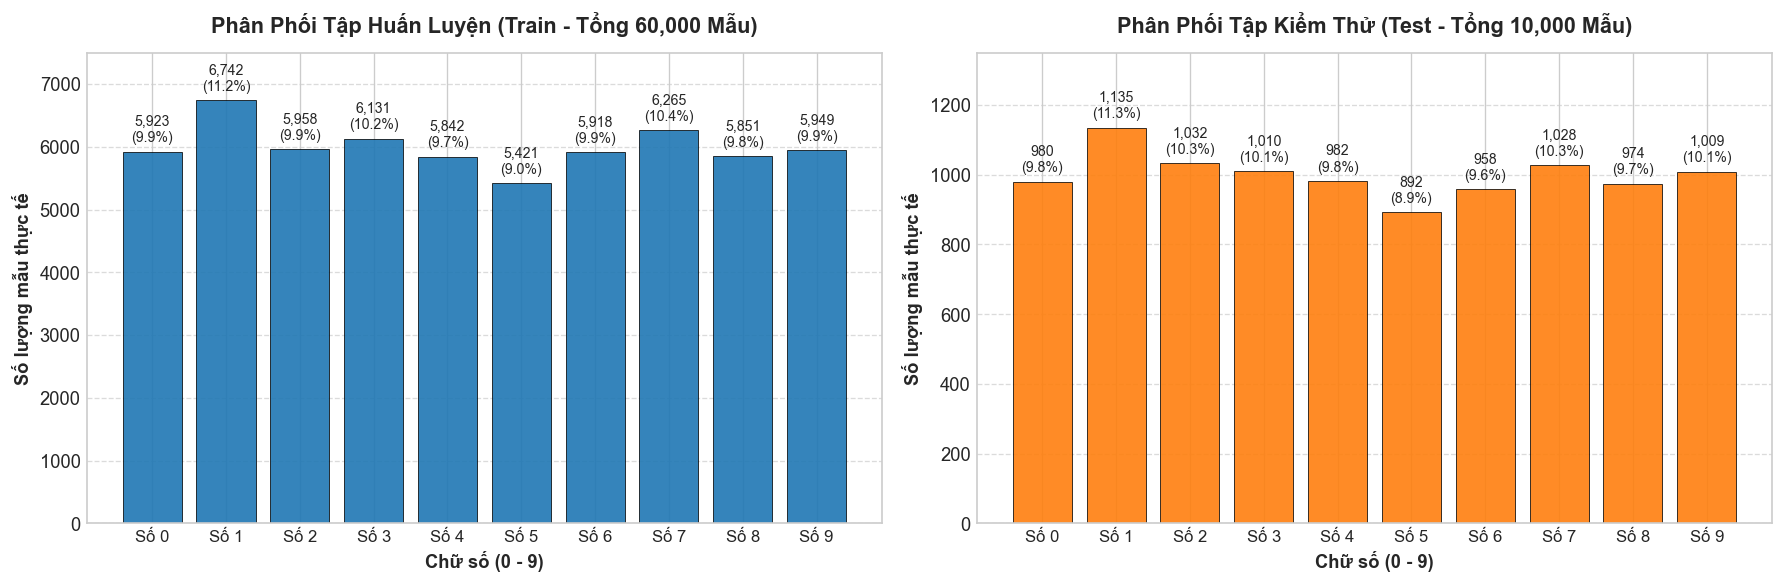

Đã lưu biểu đồ: ../reports/figures/fig_01_mnist_class_distribution.png


In [3]:
# Đếm tần suất từng chữ số
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

df_dist = pd.DataFrame({
    'Chữ số': [str(i) for i in range(10)],
    'Tập Train': train_counts.values,
    'Tỉ lệ Train (%)': (train_counts.values / len(y_train) * 100).round(2),
    'Tập Test': test_counts.values,
    'Tỉ lệ Test (%)': (test_counts.values / len(y_test) * 100).round(2)
})
display(df_dist)

# Vẽ 2 biểu đồ con cạnh nhau thể hiện chính xác số lượng thực tế và tỉ lệ %
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 1: Tập Huấn Luyện (Train - 60,000 mẫu)
bars1 = ax1.bar(train_counts.index, train_counts.values, color='#1f77b4', alpha=0.9, edgecolor='black', linewidth=0.5)
ax1.set_title('Phân Phối Tập Huấn Luyện (Train - Tổng 60,000 Mẫu)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Chữ số (0 - 9)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Số lượng mẫu thực tế', fontsize=11, fontweight='bold')
ax1.set_xticks(range(10))
ax1.set_xticklabels([f"Số {i}" for i in range(10)], fontsize=10)
ax1.set_ylim(0, 7500)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars1:
    h = bar.get_height()
    pct = h / len(y_train) * 100
    ax1.annotate(f'{h:,}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

# Biểu đồ 2: Tập Kiểm Thử (Test - 10,000 mẫu)
bars2 = ax2.bar(test_counts.index, test_counts.values, color='#ff7f0e', alpha=0.9, edgecolor='black', linewidth=0.5)
ax2.set_title('Phân Phối Tập Kiểm Thử (Test - Tổng 10,000 Mẫu)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Chữ số (0 - 9)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Số lượng mẫu thực tế', fontsize=11, fontweight='bold')
ax2.set_xticks(range(10))
ax2.set_xticklabels([f"Số {i}" for i in range(10)], fontsize=10)
ax2.set_ylim(0, 1350)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars2:
    h = bar.get_height()
    pct = h / len(y_test) * 100
    ax2.annotate(f'{h:,}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_01_mnist_class_distribution.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")


**Nhận xét phân phối:**  
Tập dữ liệu phân bố rất đồng đều giữa các chữ số: mỗi chữ số có khoảng 5,400 đến 6,700 mẫu ở tập train (~9% đến 11%) và khoảng 890 đến 1,135 mẫu ở tập test. Chữ số 1 xuất hiện nhiều nhất (6,742 mẫu train) trong khi chữ số 5 ít nhất (5,421 mẫu train). Đây là tập dữ liệu cân bằng lý tưởng, không cần áp dụng kỹ thuật oversampling hay undersampling.


### 3. Thư Viện Mẫu Chữ Số Viết Tay (10 × 10 Grid)
Hiển thị một lưới 100 mẫu ngẫu nhiên: 10 hàng tương ứng với 10 chữ số từ 0 đến 9, mỗi hàng gồm 10 mẫu viết tay thực tế khác nhau để thấy được sự đa dạng về phong cách viết, nét dày mỏng và độ nghiêng.


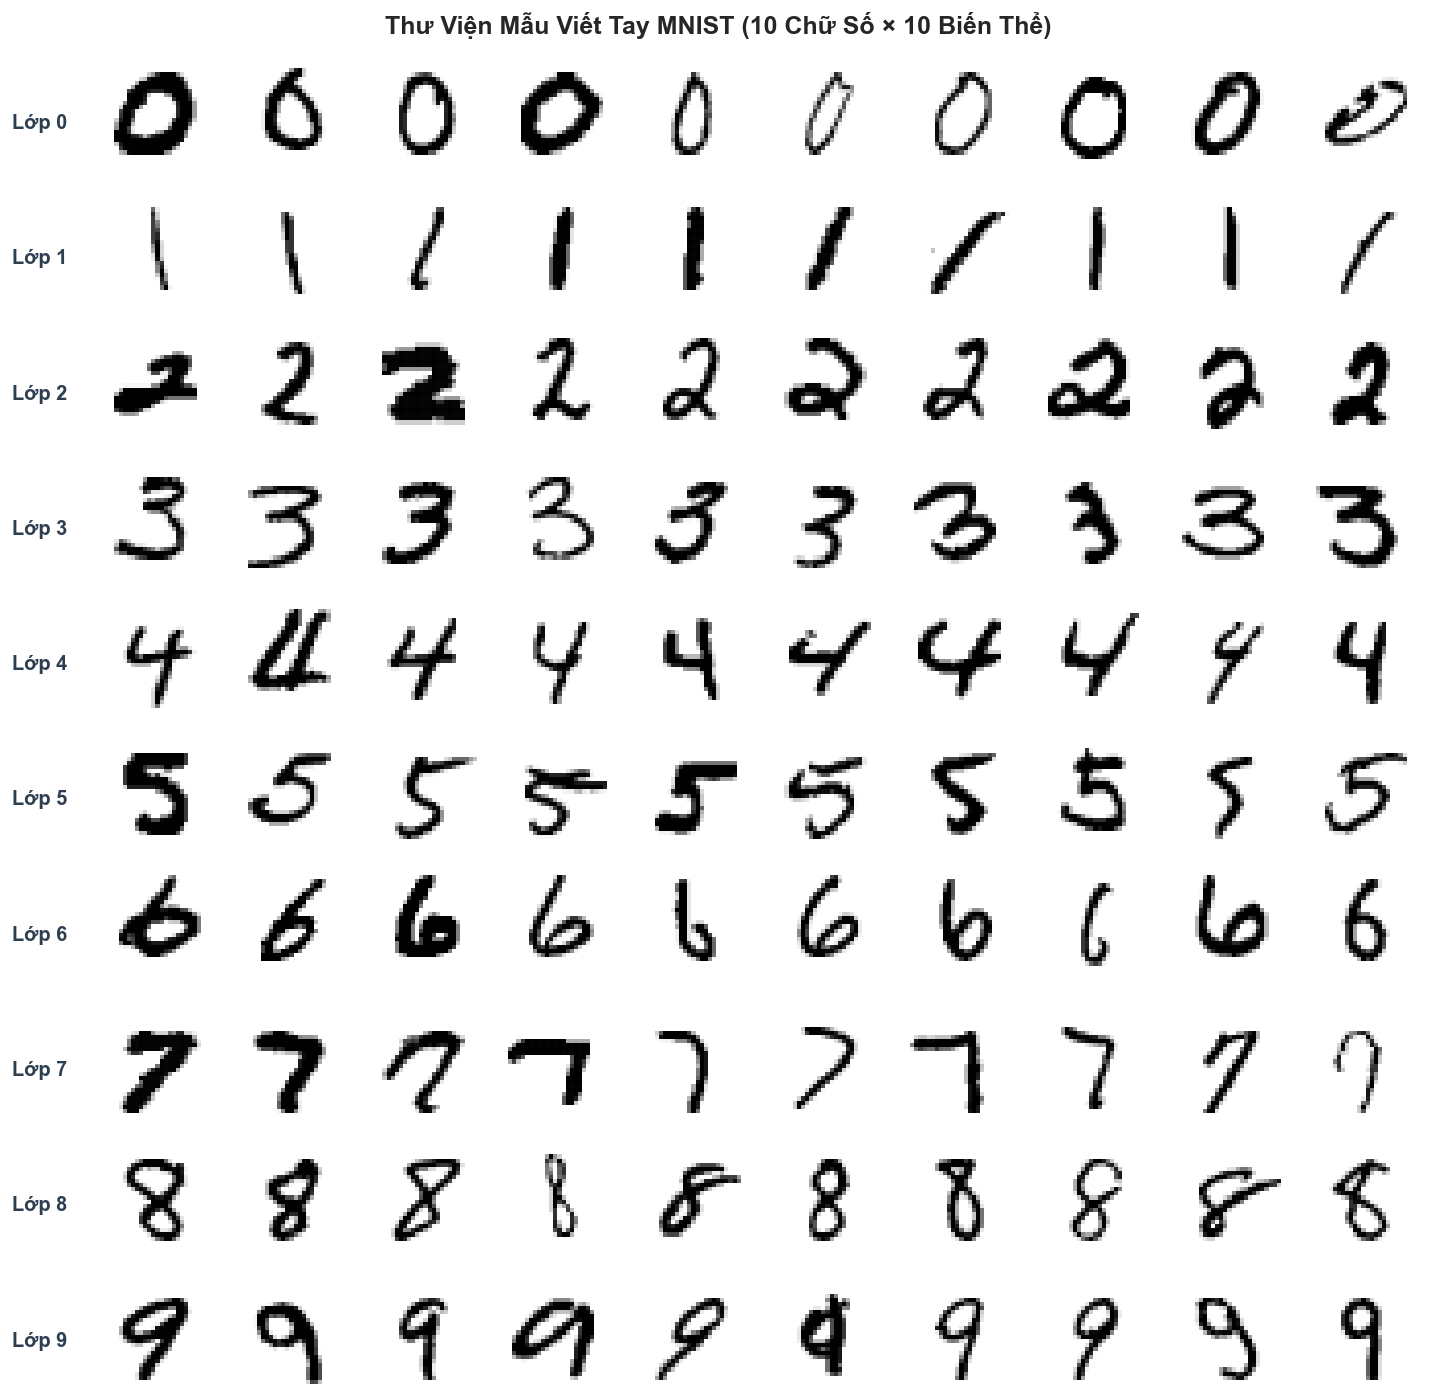

Đã lưu biểu đồ: ../reports/figures/fig_02_mnist_sample_grid.png


In [4]:
fig, axes = plt.subplots(10, 10, figsize=(12, 12))

for digit in range(10):
    digit_indices = np.where(y_train == digit)[0]
    sample_indices = np.random.choice(digit_indices, size=10, replace=False)
    
    for col, idx in enumerate(sample_indices):
        ax = axes[digit, col]
        # Sử dụng cmap='gray_r' để nét chữ màu đen trên nền giấy trắng giúp quan sát trực quan nhất
        ax.imshow(X_train[idx], cmap='gray_r', interpolation='nearest')
        ax.axis('off')
        
        if col == 0:
            ax.text(-8, 16, f"Lớp {digit}", fontsize=12, fontweight='bold', va='center', ha='right', color='#2c3e50')

plt.tight_layout()
fig.subplots_adjust(top=0.94)
plt.suptitle('Thư Viện Mẫu Viết Tay MNIST (10 Chữ Số × 10 Biến Thể)', fontsize=15, fontweight='bold', y=0.97)
fig_path = os.path.join(FIGURES_DIR, 'fig_02_mnist_sample_grid.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")
